<!-- gs-watermark -->
> **© 2026 Gokaran Shukla** · part of [hopforge](https://github.com/Gokaran-Shukla/hopforge) · MIT License — any reuse must keep this copyright notice and credit the author.

# 15 · Nonlinear Hall effect, orbital magnetism and optical conductivity

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import hopforge as hf
M = hf.models
%matplotlib inline
from hopforge import response as R

## 1. Berry curvature dipole of a tilted, strained massive Dirac model

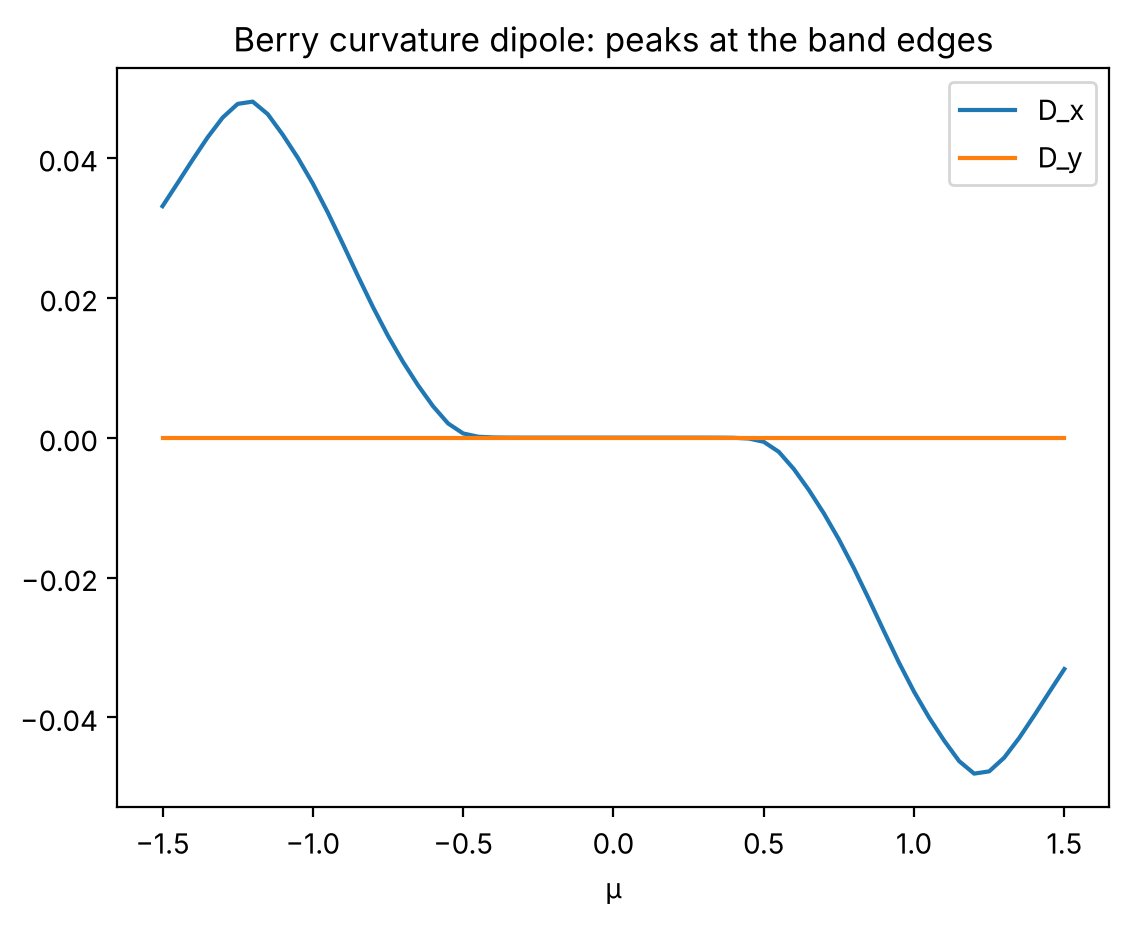

In [2]:
def tilted(tilt=0.4, strain=0.3, m=1.5):
    q = M.qwz(m)
    q.add_hopping_matrix(-0.5j * tilt * np.eye(2), ["a", "b"], ["a", "b"], [1, 0])   # tilt: + tilt sin kx
    q.add_hopping_matrix(0.5 * strain * hf.pauli('z'), ["a", "b"], ["a", "b"], [1, 0])  # anisotropic mass
    return q
q = tilted()
mus = np.linspace(-1.5, 1.5, 61)
D = R.berry_curvature_dipole(q, mus, kT=0.03, nk=250, n_jobs=-1)
plt.plot(mus, D[:, 0], label="D_x"); plt.plot(mus, D[:, 1], label="D_y")
plt.legend(); plt.xlabel("μ"); plt.title("Berry curvature dipole: peaks at the band edges");

In [3]:
print("no tilt  :", R.berry_curvature_dipole(tilted(tilt=0), 0.8, kT=0.03, nk=200)[0])
print("with tilt:", R.berry_curvature_dipole(tilted(), 0.8, kT=0.03, nk=200)[0])

no tilt  : [-4.86243424e-17  6.64217028e-19]
with tilt: [-1.86733687e-02 -4.89679630e-18]


## 2. Valley-contrasting orbital moment of gapped graphene

m(K) = 0.328125   m(K') = -0.32812499999999994


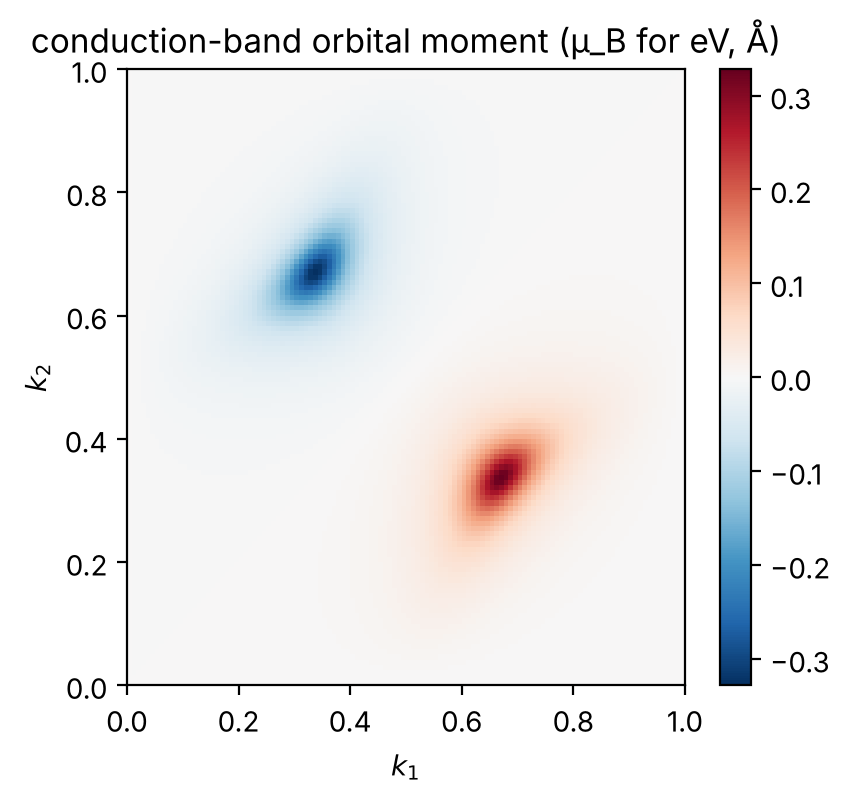

In [4]:
g = M.honeycomb(delta=0.3)
k1, k2 = np.meshgrid(np.linspace(0, 1, 120, endpoint=False), np.linspace(0, 1, 120, endpoint=False), indexing="ij")
E, Om, m = R.orbital_moment(g, np.stack([k1.ravel(), k2.ravel()], 1))
hf.plot_kmap(m[:, 1].reshape(120, 120) * R.MU_B_PER_UNIT, title="conduction-band orbital moment (μ_B for eV, Å)");
K, Kp = g.special_points["K"], g.special_points["K'"]
print("m(K) =", R.orbital_moment(g, K)[2][0, 1]*R.MU_B_PER_UNIT, "  m(K') =", R.orbital_moment(g, Kp)[2][0, 1]*R.MU_B_PER_UNIT)

## 3. Modern orbital magnetisation and the Středa formula

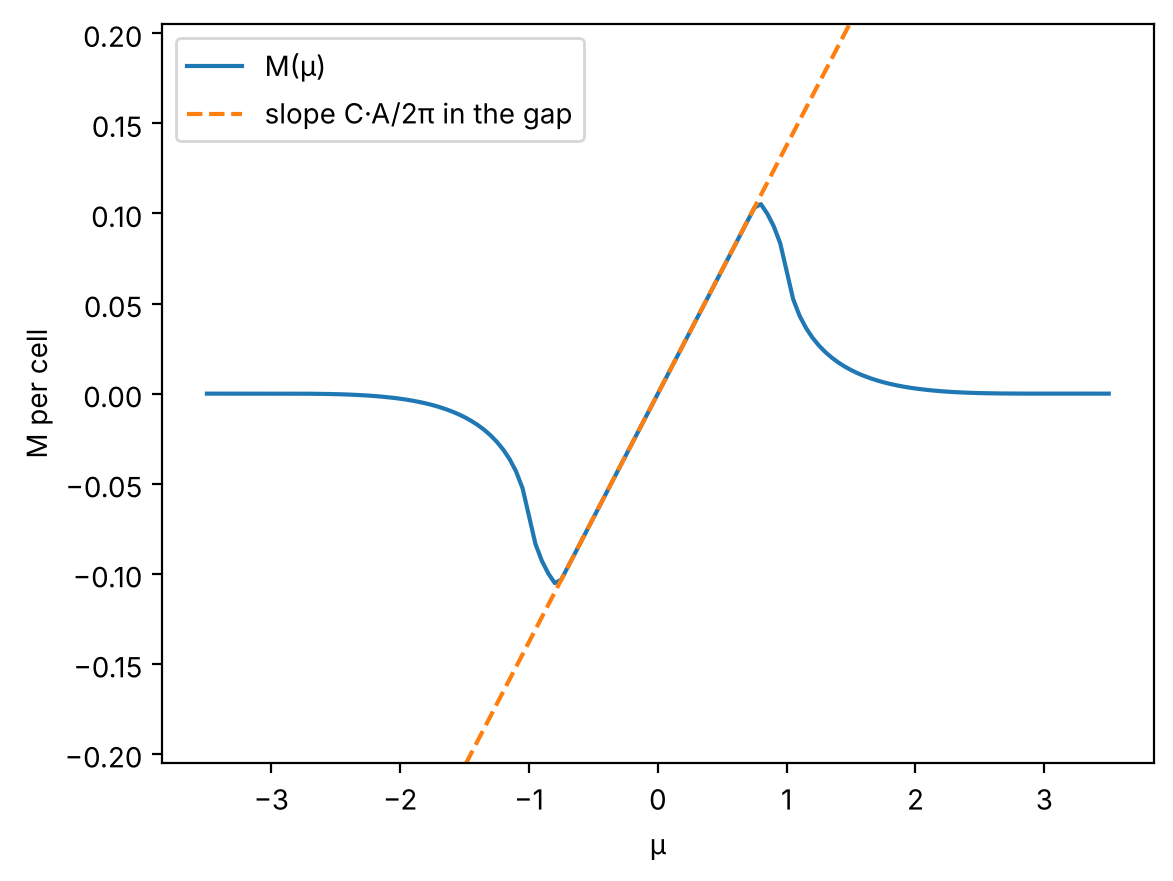

In [5]:
h = M.haldane(t2=0.15)
mus = np.linspace(-3.5, 3.5, 141)
Mo = R.orbital_magnetization(h, mus, kT=0.01, nk=150, n_jobs=-1)
plt.plot(mus, Mo, label="M(μ)")
plt.plot(mus, (mus) * h.lat.cell_volume / (2*np.pi) + Mo[70], "--", label="slope C·A/2π in the gap")
plt.legend(); plt.xlabel("μ"); plt.ylabel("M per cell"); plt.ylim(Mo.min()-0.1, Mo.max()+0.1);

## 4. Optical conductivity of graphene: the universal plateau and Pauli blocking

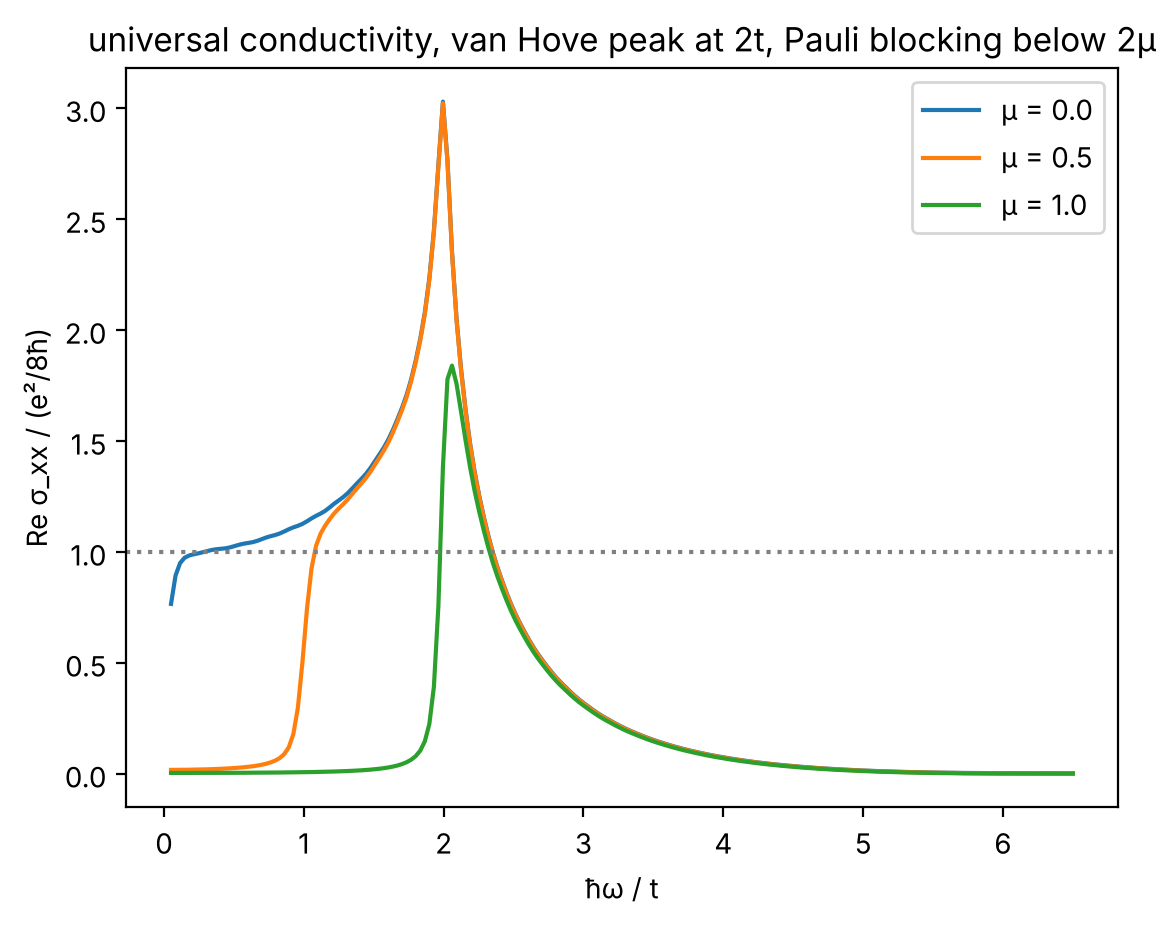

In [6]:
om = np.linspace(0.05, 6.5, 200)
for mu in (0.0, 0.5, 1.0):
    s = R.optical_conductivity(M.honeycomb(), om, mu=mu, kT=0.01, nk=300, eta=0.03, n_jobs=-1)
    plt.plot(om, s.real / 0.125, label=f"μ = {mu}")
plt.axhline(1, c="gray", ls=":"); plt.legend(); plt.xlabel("ħω / t"); plt.ylabel("Re σ_xx / (e²/8ħ)")
plt.title("universal conductivity, van Hove peak at 2t, Pauli blocking below 2μ");

## 5. Optical Hall conductivity of a Chern insulator

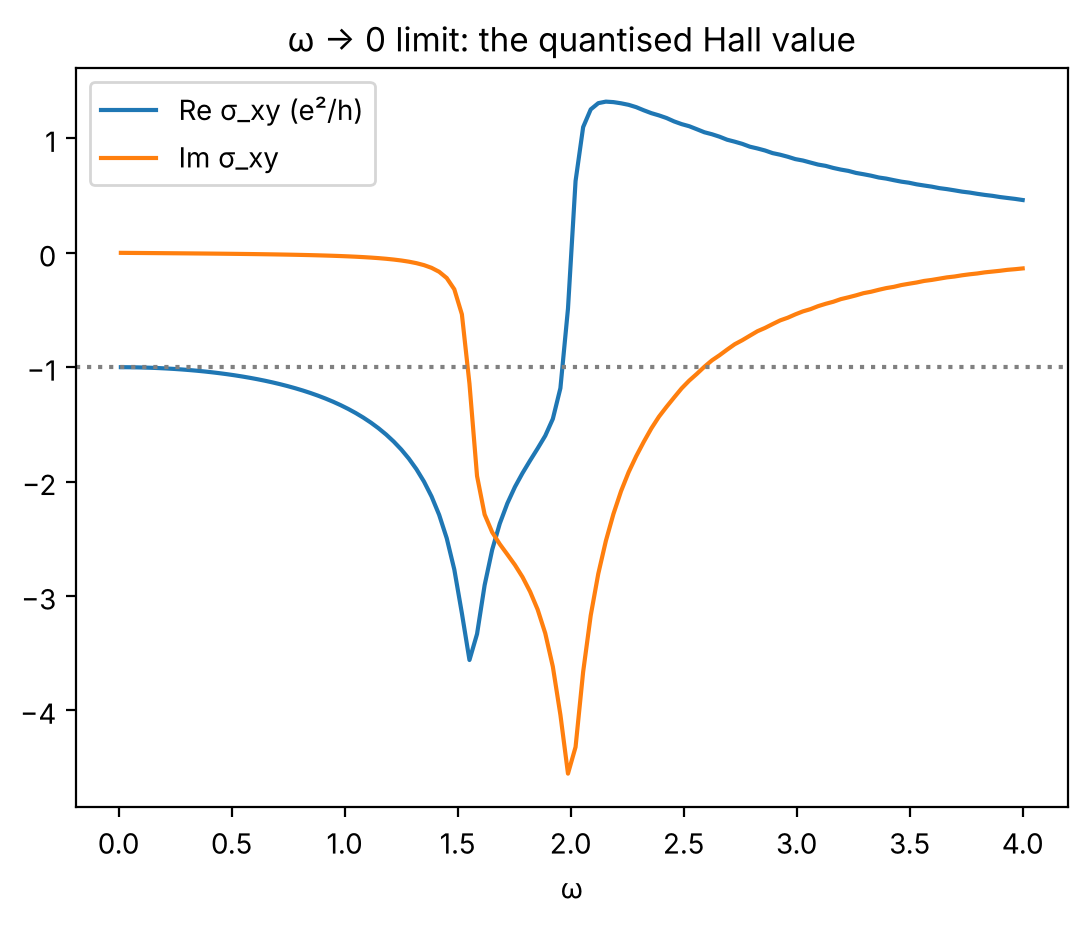

In [7]:
om = np.linspace(0.01, 4, 120)
s = R.optical_conductivity(M.haldane(t2=0.15), om, mu=0.0, nk=200, eta=0.03, component="xy", n_jobs=-1)
plt.plot(om, 2*np.pi*s.real, label="Re σ_xy (e²/h)"); plt.plot(om, 2*np.pi*s.imag, label="Im σ_xy")
plt.axhline(-1, c="gray", ls=":"); plt.legend(); plt.xlabel("ω"); plt.title("ω → 0 limit: the quantised Hall value");

## Exercises
1. Show that the BCD vanishes for the C3-symmetric gapped honeycomb model.
2. Compute the orbital magnetisation of the d-wave altermagnet with Rashba SOC.
3. Add a Drude term (`drude_tau=`) to the doped-graphene optical conductivity.

---
## Quiz 15: Nonlinear, orbital, optical

Twenty multiple-choice questions on this module. Run the next cell for a clickable
version (needs `ipywidgets`), or use the text version below it and grade yourself with
`quiz.check({1: 'a', 2: 'c', ...})`.

In [8]:
quiz = hf.Quiz(15)
quiz.interactive()

In [9]:
quiz.show()

=== Quiz 15: Nonlinear Hall effect, orbital magnetism and optical conductivity ===

Q1. The Berry curvature dipole is
   (a) the orbital moment
   (b) int Omega
   (c) D_c = int sum f d_{k_c} Omega
   (d) the Drude weight

Q2. A nonlinear Hall current from the BCD requires
   (a) a superconductor
   (b) broken time reversal only
   (c) broken inversion symmetry but can survive time reversal
   (d) a magnetic field

Q3. In 2D with C3 symmetry (e.g. gapped graphene), the BCD
   (a) equals C
   (b) is maximal
   (c) vanishes; strain or tilt is needed
   (d) is quantised

Q4. The BCD can be written as a Fermi-surface integral because
   (a) Omega is constant
   (b) of C3
   (c) int f dOmega = int (-df/dE) v Omega after integrating by parts
   (d) of TRS

Q5. Bilayer WSe2 / few-layer WTe2 are known platforms for
   (a) the nonlinear Hall effect
   (b) superconductivity only
   (c) Hofstadter butterflies
   (d) Fermi arcs

Q6. The orbital magnetic moment of a Bloch state is
   (a) Omega time

In [10]:
my_answers = {
    1: '',
    2: '',
    3: '',
    4: '',
    5: '',
    6: '',
    7: '',
    8: '',
    9: '',
    10: '',
    11: '',
    12: '',
    13: '',
    14: '',
    15: '',
    16: '',
    17: '',
    18: '',
    19: '',
    20: '',
}
quiz.check(my_answers)

Q1: (no answer)
Q2: (no answer)
Q3: (no answer)
Q4: (no answer)
Q5: (no answer)
Q6: (no answer)
Q7: (no answer)
Q8: (no answer)
Q9: (no answer)
Q10: (no answer)
Q11: (no answer)
Q12: (no answer)
Q13: (no answer)
Q14: (no answer)
Q15: (no answer)
Q16: (no answer)
Q17: (no answer)
Q18: (no answer)
Q19: (no answer)
Q20: (no answer)

Score: 0 / 20


0